# Module project: build an automatic differentiation engine

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-5-microdiff.ipynb`, attached to this lesson. It builds and runs the whole project; on the course's web page it opens in Google Colab.
- **Finished code**: the `projects/microdiff` folder in the course files, to check your work.
- **Data**: No download: the data is generated by `train.py` (two interleaved half-moons).

In [ ]:
%pip install -q torch matplotlib

In the last project you wrote every gradient by hand. Section 8.2 shows how to stop doing that: if each operation knows
its own small derivative, a program can apply the chain rule for you, for **any** function you write. That's automatic
differentiation, the engine inside PyTorch, JAX and TensorFlow.

In this project you build one, in about 150 lines of Python, in **both** modes the book describes: reverse mode (what
PyTorch's `backward()` does) and forward mode (dual numbers). You'll differentiate the book's own example, draw its
computation graph, check everything against PyTorch, and train a small neural network made of nothing but your own
`Value` objects. The notebook attached above builds and runs the whole project; the reference code is in the course
files under `projects/microdiff`.

## What you'll build

```mermaid
flowchart LR
    A[engine.py<br/>Value: reverse mode<br/>Dual: forward mode] --> B[demo.py<br/>book example 8.49,<br/>3 ways + graph]
    A --> C[nn.py<br/>neurons made of Values]
    C --> D[train.py<br/>check vs PyTorch,<br/>train on two moons]
```

## Set up the project

```bash
mkdir microdiff && cd microdiff
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

```text
microdiff/
    .gitignore
    README.md
    demo.py
    engine.py
    nn.py
    requirements.txt
    train.py
```

In [2]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [3]:
%%writefile .gitignore
outputs/
__pycache__/
.venv/

Writing .gitignore


## Step 1: the engine

**Reverse mode.** A `Value` holds a number, its gradient, the values it was computed from (its parents), and a small
function `_backward` that knows the **local** derivative of the one operation that made it. For `out = a * b`,
`_backward` adds `b × out.grad` to `a.grad` and `a × out.grad` to `b.grad`. Nothing more.

`backward()` then does what section 8.2.2 describes: sort the graph so every node comes after its inputs (a topological
order), set the output's gradient to 1, and call `_backward` on every node from the output back to the inputs. One pass
gives the derivative of the output with respect to **every** input.

Two details matter:

- Gradients are **added** (`+=`), never assigned: a value used twice (like `v = x1 * x2` below, used by both `+` and
  `exp`) receives gradient from both uses.
- `__radd__`, `__rsub__` and friends let you write `2 * x` as well as `x * 2`.

**Forward mode.** A `Dual` number carries a value **and** its derivative, and every operation updates both at once
(section 8.2.1). To get `∂f/∂x1` you start with `x1` carrying derivative 1 and `x2` carrying 0, and run the function
once. For `∂f/∂x2`, you run it again with the seeds swapped.

In [4]:
%%writefile engine.py
"""microdiff: automatic differentiation for single numbers (Bishop, section 8.2), in two modes.

Reverse mode (Value): every operation records its inputs and how to send a gradient back to them.
backward() visits the graph from the output to the inputs, once. Cost: one backward pass per OUTPUT.

Forward mode (Dual): every number carries its derivative along with it, computed at the same time as the value.
Cost: one forward pass per INPUT.
"""
import math


class Value:
    def __init__(self, data, parents=(), op="", name=""):
        self.data, self.grad = float(data), 0.0
        self._parents, self._op, self.name = parents, op, name
        self._backward = lambda: None

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad                   # d(a+b)/da = 1
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad      # d(ab)/da = b
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,), f"^{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def _unary(self, value, derivative, op):
        out = Value(value, (self,), op)
        def _backward():
            self.grad += derivative * out.grad
        out._backward = _backward
        return out

    def exp(self):
        e = math.exp(self.data)
        return self._unary(e, e, "exp")

    def log(self):
        return self._unary(math.log(self.data), 1 / self.data, "log")

    def sin(self):
        return self._unary(math.sin(self.data), math.cos(self.data), "sin")

    def tanh(self):
        t = math.tanh(self.data)
        return self._unary(t, 1 - t * t, "tanh")

    def relu(self):
        return self._unary(max(0.0, self.data), float(self.data > 0), "relu")

    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __truediv__(self, other): return self * other ** -1
    __radd__, __rmul__ = __add__, __mul__
    def __rsub__(self, other): return Value(other) - self

    def graph(self):
        """All nodes, ordered so that every node comes after its parents (a topological order)."""
        order, seen = [], set()
        def visit(v):
            if id(v) not in seen:
                seen.add(id(v))
                for p in v._parents:
                    visit(p)
                order.append(v)
        visit(self)
        return order

    def backward(self):
        order = self.graph()
        for v in order:
            v.grad = 0.0
        self.grad = 1.0                             # d(output)/d(output)
        for v in reversed(order):                   # outputs first, inputs last
            v._backward()

    def to_mermaid(self):
        """The computation graph as a Mermaid diagram (GitHub draws these in README files)."""
        lines, number = ["flowchart LR"], {}
        for v in self.graph():
            number[id(v)] = len(number)
            label = (v.name or v._op or "const") + f"<br/>value {v.data:.3g}<br/>grad {v.grad:.3g}"
            lines.append(f'    n{number[id(v)]}["{label}"]')
            for p in v._parents:
                lines.append(f"    n{number[id(p)]} --> n{number[id(v)]}")
        return "\n".join(lines)


class Dual:
    """Forward mode: a number a + b*eps with eps^2 = 0. 'b' is the derivative, carried along."""
    def __init__(self, value, deriv=0.0):
        self.value, self.deriv = value, deriv

    def __add__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.value + o.value, self.deriv + o.deriv)

    def __sub__(self, o):
        return self + o * -1

    def __mul__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.value * o.value, self.deriv * o.value + self.value * o.deriv)

    def exp(self):
        e = math.exp(self.value)
        return Dual(e, e * self.deriv)

    def sin(self):
        return Dual(math.sin(self.value), math.cos(self.value) * self.deriv)

    def tanh(self):
        t = math.tanh(self.value)
        return Dual(t, (1 - t * t) * self.deriv)

    __radd__, __rmul__ = __add__, __mul__

Writing engine.py


## Step 2: the book's example, three ways

Equation 8.49 is the example section 8.2 works through by hand: `f(x1, x2) = x1 x2 + exp(x1 x2) − sin(x2)`.

In [5]:
%%writefile demo.py
"""A small function, differentiated three ways: reverse mode, forward mode, and PyTorch."""
import torch
from engine import Value, Dual


def f(x1, x2):
    """The example of section 8.2.1 (equation 8.49): f = x1 x2 + exp(x1 x2) - sin(x2)."""
    v = x1 * x2
    return v + v.exp() - x2.sin()


x1, x2 = Value(2.0, name="x1"), Value(0.5, name="x2")
y = f(x1, x2)
y.backward()
print(f"reverse mode:  f = {y.data:.6f}, df/dx1 = {x1.grad:.6f}, df/dx2 = {x2.grad:.6f}  (one backward pass)")

d1 = f(Dual(2.0, 1.0), Dual(0.5, 0.0)).deriv                 # seed x1: one pass per input
d2 = f(Dual(2.0, 0.0), Dual(0.5, 1.0)).deriv
print(f"forward mode:                    df/dx1 = {d1:.6f}, df/dx2 = {d2:.6f}  (two forward passes)")

t1, t2 = torch.tensor(2.0, requires_grad=True), torch.tensor(0.5, requires_grad=True)
v = t1 * t2
(v + v.exp() - t2.sin()).backward()
print(f"PyTorch:                         df/dx1 = {t1.grad:.6f}, df/dx2 = {t2.grad:.6f}")
print()
print(y.to_mermaid())

Writing demo.py


In [6]:
!python demo.py

reverse mode:  f = 3.238856, df/dx1 = 1.859141, df/dx2 = 6.558981  (one backward pass)
forward mode:                    df/dx1 = 1.859141, df/dx2 = 6.558981  (two forward passes)
PyTorch:                         df/dx1 = 1.859141, df/dx2 = 6.558981

flowchart LR
    n0["x1<br/>value 2<br/>grad 1.86"]
    n1["x2<br/>value 0.5<br/>grad 6.56"]
    n2["*<br/>value 1<br/>grad 3.72"]
    n0 --> n2
    n1 --> n2
    n3["exp<br/>value 2.72<br/>grad 1"]
    n2 --> n3
    n4["+<br/>value 3.72<br/>grad 1"]
    n2 --> n4
    n3 --> n4
    n5["sin<br/>value 0.479<br/>grad -1"]
    n1 --> n5
    n6["const<br/>value -1<br/>grad 0.479"]
    n7["*<br/>value -0.479<br/>grad 1"]
    n5 --> n7
    n6 --> n7
    n8["+<br/>value 3.24<br/>grad 1"]
    n4 --> n8
    n7 --> n8


All three methods agree to six decimals. Notice the costs: reverse mode needed **one** backward pass for both
derivatives, while forward mode needed **two** forward passes, one per input. A neural network has one output (the loss)
and millions of inputs (the weights), so reverse mode wins by a factor of millions. That's why training uses it.

The last part of the output is the computation graph as a Mermaid diagram. Paste it into a README on GitHub inside a
` ```mermaid ` block and GitHub draws it: you'll see `x1 * x2` computed once and used twice, with gradient 3.72 flowing
back into it from both uses. Compare it with the book's figure of the same function.

## Step 3: a network made of Values

A neuron is a weighted sum of its inputs plus a bias, through `tanh`. A layer is a list of neurons, a network a list of
layers. Because every operation goes through `Value`, the whole network is differentiable for free.

In [7]:
%%writefile nn.py
"""A neural network made of nothing but Value objects."""
import random
from engine import Value


class Neuron:
    def __init__(self, n_in, act=True):
        self.w = [Value(random.gauss(0, n_in ** -0.5)) for _ in range(n_in)]
        self.b = Value(0.0)
        self.act = act

    def __call__(self, x):
        a = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return a.tanh() if self.act else a

    def parameters(self):
        return self.w + [self.b]


class MLP:
    def __init__(self, sizes):
        self.layers = [[Neuron(a, act=(i < len(sizes) - 2)) for _ in range(b)]
                       for i, (a, b) in enumerate(zip(sizes, sizes[1:]))]

    def __call__(self, x):
        for layer in self.layers:
            x = [neuron(x) for neuron in layer]
        return x[0]

    def parameters(self):
        return [p for layer in self.layers for n in layer for p in n.parameters()]

Writing nn.py


Before training, `train.py` compares your engine's gradients for all 105 parameters with PyTorch's, on the same weights
and data. Then it trains with gradient descent and momentum on two interleaved half-moons, a classic problem that no
straight line can separate.

In [8]:
%%writefile train.py
"""Train a microdiff network to separate two interleaved half-moons, after checking its gradients against PyTorch."""
import math
import random
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from engine import Value
from nn import MLP

random.seed(0)
points, labels = [], []
for i in range(40):                                       # two interleaved half-moons, 40 points each
    a = math.pi * i / 39
    points.append((math.cos(a) - 0.5 + random.gauss(0, 0.1), math.sin(a) - 0.25 + random.gauss(0, 0.1)))
    labels.append(1)
    points.append((0.5 - math.cos(a) + random.gauss(0, 0.1), 0.25 - math.sin(a) + random.gauss(0, 0.1)))
    labels.append(-1)

model = MLP([2, 8, 8, 1])
params = model.parameters()
print(f"{len(params)} parameters, {len(points)} points")


def loss_and_accuracy():
    """Hinge-free and simple: the mean squared error between the output and the label (+1 or -1)."""
    outs = [model([Value(x), Value(y)]) for x, y in points]
    loss = sum(((o - t) ** 2 for o, t in zip(outs, labels)), Value(0.0)) * (1 / len(points))
    acc = sum((o.data > 0) == (t > 0) for o, t in zip(outs, labels)) / len(points)
    return loss, acc


# Check the very first gradient against PyTorch on the same weights
loss, _ = loss_and_accuracy()
loss.backward()
W = [torch.tensor([[w.data for w in n.w] for n in layer], dtype=torch.float64, requires_grad=True) for layer in model.layers]
B = [torch.tensor([n.b.data for n in layer], dtype=torch.float64, requires_grad=True) for layer in model.layers]
h = torch.tensor(points, dtype=torch.float64)
for i, (w, b) in enumerate(zip(W, B)):
    h = h @ w.T + b
    h = torch.tanh(h) if i < len(W) - 1 else h
((h[:, 0] - torch.tensor(labels, dtype=torch.float64)) ** 2).mean().backward()
torch_grads = [g for w, b in zip(W, B) for row_w, gb in zip(w.grad, b.grad) for g in [*row_w.tolist(), gb.item()]]
print(f"largest difference from PyTorch's gradients: {max(abs(p.grad - g) for p, g in zip(params, torch_grads)):.1e}")

velocity = [0.0] * len(params)
for step in range(1, 151):
    loss, acc = loss_and_accuracy()
    loss.backward()
    for i, p in enumerate(params):                        # gradient descent with momentum (section 7.3.1)
        velocity[i] = 0.9 * velocity[i] - 0.05 * p.grad
        p.data += velocity[i]
    if step in (1, 25, 50, 100, 150):
        print(f"step {step:3d}: loss {loss.data:.4f}, accuracy {acc:.3f}")

Path("outputs").mkdir(exist_ok=True)
grid = [(x / 10, y / 10) for y in range(-15, 16) for x in range(-20, 21)]
z = [model([Value(x), Value(y)]).data for x, y in grid]
plt.figure(figsize=(5, 5))
plt.tricontourf([g[0] for g in grid], [g[1] for g in grid], z, levels=[-10, 0, 10], colors=["#f3c7c0", "#c0d7f3"])
plt.scatter(*zip(*points), c=["C0" if t > 0 else "C3" for t in labels], s=12)
plt.title("decision regions learned by microdiff"); plt.axis("equal")
plt.tight_layout(); plt.savefig("outputs/moons.png", dpi=110)
print("saved outputs/moons.png")

Writing train.py


In [9]:
!python train.py

105 parameters, 80 points


largest difference from PyTorch's gradients: 5.6e-16


step   1: loss 1.7204, accuracy 0.113


step  25: loss 0.3359, accuracy 0.875


step  50: loss 0.1400, accuracy 0.950


step 100: loss 0.0496, accuracy 1.000


step 150: loss 0.0450, accuracy 1.000


saved outputs/moons.png


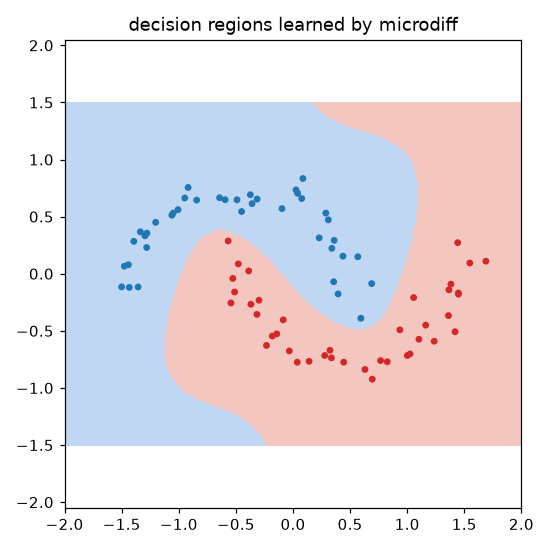

In [10]:
from IPython.display import Image
Image('outputs/moons.png')

The gradients match PyTorch to about 1e-16, the limit of double precision. The network separates the moons perfectly
after about 100 steps, with a curved boundary no linear model could draw.

It also took about half a minute, for 80 points and 105 parameters. Each `Value` is a Python object, and each step builds
and walks a graph of tens of thousands of them. PyTorch applies exactly the same reverse-mode idea, but each node in its
graph is a whole **tensor** operation (a matrix multiplication, say) running in optimized C++. Same algorithm, a
thousand times fewer nodes. That's the next step for the library in this course's big project.

## Step 4: write the README and publish

Put the Mermaid graph in your README: it makes the project look as good as it is.

In [11]:
%%writefile README.md
# microdiff

A small automatic-differentiation engine in pure Python, with both modes of section 8.2: reverse mode (a computation
graph with `backward()`, like PyTorch) and forward mode (dual numbers). It draws its own computation graphs as Mermaid
diagrams, and trains a small neural network.

![moons](outputs/moons.png)

## Results

| check | result |
|---|---|
| book example f = x1 x2 + exp(x1 x2) - sin(x2): reverse mode, forward mode, PyTorch | identical to 6 decimals |
| gradients of a 105-parameter network vs PyTorch (float64) | largest difference 6e-16 |
| two-moons classification, 2-8-8-1 tanh network, 150 steps | 100% training accuracy |

## The computation graph of the example

```mermaid
flowchart LR
    n0["x1<br/>value 2<br/>grad 1.86"]
    n1["x2<br/>value 0.5<br/>grad 6.56"]
    n2["*<br/>value 1<br/>grad 3.72"]
    n0 --> n2
    n1 --> n2
    n3["exp<br/>value 2.72<br/>grad 1"]
    n2 --> n3
    n4["+<br/>value 3.72<br/>grad 1"]
    n2 --> n4
    n3 --> n4
    n5["sin<br/>value 0.479<br/>grad -1"]
    n1 --> n5
    n6["const<br/>value -1<br/>grad 0.479"]
    n7["*<br/>value -0.479<br/>grad 1"]
    n5 --> n7
    n6 --> n7
    n8["+<br/>value 3.24<br/>grad 1"]
    n4 --> n8
    n7 --> n8
```

## Run it

```bash
pip install -r requirements.txt
python demo.py     # the book's example, three ways, and its graph
python train.py    # a neural network made of Value objects (about 30 seconds)
```

## What I learned

- Reverse mode gets all the derivatives of one output in a single backward pass, which is why it trains networks;
  forward mode needs one pass per input.
- Each operation only needs to know its own local derivative; the chain rule does the rest.
- Working one number at a time is very slow in Python. Real frameworks apply the same idea to whole tensors.

Based on section 8.2 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "microdiff: reverse and forward mode automatic differentiation"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/microdiff.git
git push -u origin main
```

## Make it yours

- **More operations.** Add `cos`, `sigmoid` and division by a `Value`, each with a test against PyTorch.
- **Second derivatives.** Make `_backward` build its result out of `Value` operations too, so you can call `backward()`
  on a gradient. Check `d²f/dx1²` for the example against `torch.autograd.grad(..., create_graph=True)`.
- **Count the cost.** Write a function with 100 inputs and one output. Count how many operations forward mode needs for
  the full gradient, and how many reverse mode needs. Plot both as the number of inputs grows.
- **Tests and CI.** Turn the PyTorch comparisons into `pytest` tests and run them with GitHub Actions on every push.

## On your CV

> **microdiff** (Python): automatic differentiation engine with reverse mode (computation graph, topological backward
> pass) and forward mode (dual numbers); gradients match PyTorch to 1e-16; trained a 2-layer neural network built from
> its own scalar operations; renders computation graphs as Mermaid diagrams. github.com/YOUR-USERNAME/microdiff

## Check yourself

- [ ] You can explain why gradients are accumulated with `+=`.
- [ ] You can explain why training uses reverse mode, not forward mode, in one sentence.
- [ ] Your tests compare against PyTorch.